# NGUYỄN THÀNH TRÍ - MSSV: 6451071079
## BÀI 1: XÂY DỰNG MÔ HÌNH PHÂN LỚP TRÊN BỘ DỮ LIỆU IRIS
### (DECISION TREE, NAÏVE BAYES, K-NEAREST NEIGHBORS, NEURAL NETWORK)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Thiet lap giao dien bieu do
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Da nap day du cac thu vien can thiet.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


I0000 00:00:1794277571.051176   35102 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Da nap day du cac thu vien can thiet.


I0000 00:00:1794277572.402844   35102 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Câu a: Đọc bộ dữ liệu Iris từ sklearn
Hướng dẫn: Từ thư viện sklearn import Iris và sử dụng hàm load_iris để đọc bộ dữ liệu.

In [2]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

iris = load_iris()
print("Da nap bo du lieu Iris thanh cong tu sklearn.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Da nap bo du lieu Iris thanh cong tu sklearn.


### Câu b: Khảo sát bộ dữ liệu Iris với yêu cầu sau:
- In ra tên các thuộc tính, thuộc tính phân lớp (`feature_names`, `target_names`).
- In ra số lượng mẫu, số lượng thuộc tính (`data.shape`, `target.shape`).
- In 5 mẫu dữ liệu đầu tiên (`data[]`, `target[]`).
- Thống kê count, mean, std, min, max, tứ vị phân của bộ dữ liệu (tạo dataframe và sử dụng `describe`).

In [3]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# 1. Ten cac thuoc tinh va thuoc tinh phan lop
print("Ten cac thuoc tinh dac trung (feature_names):")
print(iris.feature_names)
print("\nTen cac lop phan loai (target_names):")
print(iris.target_names)

# 2. So luong mau va so luong thuoc tinh
print("\nKich thuoc tap du lieu dac trung (data.shape):", iris.data.shape)
print("Kich thuoc tap nhan (target.shape):", iris.target.shape)

# 3. 5 mau du lieu dau tien
print("\n5 mau du lieu dac trung dau tien (data[:5]):")
print(iris.data[:5])
print("\n5 nhan tuong ung dau tien (target[:5]):")
print(iris.target[:5])

# 4. Thong ke count, mean, std, min, max, tu phan vi
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris['target'] = iris.target
df_iris['species'] = df_iris['target'].apply(lambda x: iris.target_names[x])

print("\nThong ke mo ta bo du lieu bang describe():")
display(df_iris.describe())

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Ten cac thuoc tinh dac trung (feature_names):
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Ten cac lop phan loai (target_names):
['setosa' 'versicolor' 'virginica']

Kich thuoc tap du lieu dac trung (data.shape): (150, 4)
Kich thuoc tap nhan (target.shape): (150,)

5 mau du lieu dac trung dau tien (data[:5]):
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

5 nhan tuong ung dau tien (target[:5]):
[0 0 0 0 0]

Thong ke mo ta bo du lieu bang describe():


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


### Câu c: Chuẩn hóa dữ liệu data về đoạn [0, 1]
Hướng dẫn: Gán X là data và Y là target của bộ dữ liệu. Chia mỗi giá trị của X cho giá trị lớn nhất trong cột tương ứng. Sử dụng max để lấy giá trị lớn nhất của data.

In [4]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

X = iris.data.copy()
Y = iris.target.copy()

# Lay gia tri lon nhat theo tung cot thuoc tinh
X_max = X.max(axis=0)
print("Gia tri lon nhat cua tung cot thuoc tinh (X_max):")
for col_name, max_val in zip(iris.feature_names, X_max):
    print(f"- {col_name}: {max_val}")

# Chuan hoa ve doan [0, 1] bang cach chia moi gia tri cho gia tri lon nhat trong cot
X = X / X_max

print("\n5 mau du lieu sau khi chuan hoa ve [0, 1]:")
print(np.round(X[:5], 4))
print(f"Gia tri nho nhat: {X.min():.4f}, Gia tri lon nhat: {X.max():.4f}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Gia tri lon nhat cua tung cot thuoc tinh (X_max):
- sepal length (cm): 7.9
- sepal width (cm): 4.4
- petal length (cm): 6.9
- petal width (cm): 2.5

5 mau du lieu sau khi chuan hoa ve [0, 1]:
[[0.6456 0.7955 0.2029 0.08  ]
 [0.6203 0.6818 0.2029 0.08  ]
 [0.5949 0.7273 0.1884 0.08  ]
 [0.5823 0.7045 0.2174 0.08  ]
 [0.6329 0.8182 0.2029 0.08  ]]
Gia tri nho nhat: 0.0400, Gia tri lon nhat: 1.0000


### Câu d: Chia dữ liệu thành tập train và tập test theo tỷ lệ 8:2
Hướng dẫn: Sử dụng train_test_split từ thư viện sklearn để chia X, Y thành X_train, X_test, y_train, y_test.

In [5]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

print(f"Kich thuoc tap Train: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Kich thuoc tap Test:  X_test  = {X_test.shape}, y_test  = {y_test.shape}")
print("Phan bo cac lop tren tap Train:", np.bincount(y_train))
print("Phan bo cac lop tren tap Test:", np.bincount(y_test))

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kich thuoc tap Train: X_train = (120, 4), y_train = (120,)
Kich thuoc tap Test:  X_test  = (30, 4), y_test  = (30,)
Phan bo cac lop tren tap Train: [40 40 40]
Phan bo cac lop tren tap Test: [10 10 10]


### Câu e: Sử dụng Cây quyết định (Decision Tree) để phân lớp
Yêu cầu:
- Huấn luyện mô hình phân lớp trên tập train (`DecisionTreeClassifier`).
- Dự đoán nhãn lớp cho tập test (`predict`).
- Tính và in ra Accuracy của mô hình trên tập test.
- Tính và in ra Precision, Recall, F1-score của từng lớp và trung bình của mô hình trên tập test.
- Hiển thị confusion matrix bằng heat map (bản đồ nhiệt).

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Do chinh xac Accuracy (Decision Tree): 0.9333 (93.33%)

Bao cao chi tiet danh gia mo hinh Decision Tree:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



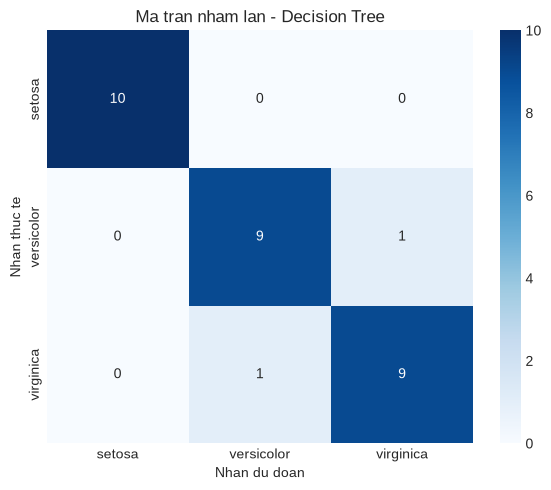

In [6]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# 1. Khoi tao va huan luyen mo hinh Cay quyet dinh
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# 2. Du doan nhan tren tap test
y_pred_dt = dt_model.predict(X_test)

# 3. Do chinh xac Accuracy
acc_dt = accuracy_score(y_test, y_pred_dt)
print(f"Do chinh xac Accuracy (Decision Tree): {acc_dt:.4f} ({acc_dt*100:.2f}%)")

# 4. Precision, Recall, F1-score
print("\nBao cao chi tiet danh gia mo hinh Decision Tree:")
print(classification_report(y_test, y_pred_dt, target_names=iris.target_names))

# 5. Ma tran nham lan (Confusion Matrix) dang heatmap
cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("Ma tran nham lan - Decision Tree", fontsize=12)
plt.xlabel("Nhan du doan", fontsize=10)
plt.ylabel("Nhan thuc te", fontsize=10)
plt.tight_layout()
plt.show()